# Member states

Roadmap step 4, part 2. What does the GRU learn about each member, and does its running summary of a member's votes track their position?

The GRU reads each member's votes in order. Its hidden state summarises their past votes, and its output is the probability that they break from their party on the next roll call. Here both are averaged over each member's **party-opposed** votes in each Congress:

- **GRU propensity** (`mean_p_gru`): the average predicted probability of defecting, each prediction made from earlier votes only;
- **average state**: the mean of the 64 hidden units.

They are compared with the member's actual defection rate and with Nokken-Poole positions. The main comparison uses the **previous Congress's** Nokken-Poole score, because a same-Congress score is fitted on the same votes and would agree partly by construction. Same-Congress scores are shown as a reference only.

Member-Congresses with fewer than 50 party-opposed votes are left out. Congresses 102 to 111 (1991 to 2010) are training years, so values there are in-sample. This is a description of voting behaviour, not of beliefs.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from voteview import load_members

warnings.filterwarnings("ignore")
COLORS = {"D": "#2a78d6", "R": "#c93b3b"}
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})
OUTPUTS = Path.cwd().parent / "outputs"
MIN_VOTES = 50
states = pd.read_parquet(OUTPUTS / "gru_member_states.parquet")
states = states[states["votes"] >= MIN_VOTES]
hidden = [c for c in states.columns if c.startswith("h") and c[1:].isdigit()]
members = load_members()[["congress", "chamber", "icpsr", "nokken_poole_dim1", "nominate_dim1"]].drop_duplicates(["congress", "chamber", "icpsr"])
states = states.merge(members, on=["congress", "chamber", "icpsr"], how="left")
# Same-Congress Nokken-Poole distance toward the other party, measured from the party median. Descriptive only.
median = states.groupby(["congress", "chamber", "party"])["nokken_poole_dim1"].transform("median")
states["np_toward_other"] = (states["nokken_poole_dim1"] - median) * np.where(states["party"] == "D", 1, -1)
states["np_extremity"] = states["nokken_poole_dim1"].abs()
# Previous-Congress Nokken-Poole, which isn't fitted on this Congress's votes. It is fitted on the previous Congress's votes,
# which the GRU has also read, so agreement with it is partly built in and is a description, not a validation. Matched by person
# and chamber; the party median is that of the previous Congress. Members without a previous Congress are left missing.
previous = load_members()
previous = previous[previous["party"].isin(["D", "R"]) & ~previous["is_delegate"]].drop_duplicates(["congress", "chamber", "icpsr"])
previous["person"] = previous["bioguide_id"].fillna("icpsr:" + previous["icpsr"].astype(str))
previous["np_prev_toward_other"] = ((previous["nokken_poole_dim1"]
                                     - previous.groupby(["congress", "chamber", "party"])["nokken_poole_dim1"].transform("median"))
                                    * np.where(previous["party"] == "D", 1, -1))
previous = previous.assign(congress=previous["congress"] + 1).drop_duplicates(["congress", "chamber", "person", "party"])
states = states.merge(previous[["congress", "chamber", "person", "party", "np_prev_toward_other"]],
                      on=["congress", "chamber", "person", "party"], how="left")
print(f"{states['np_prev_toward_other'].notna().mean():.1%} of member-Congresses have a previous-Congress Nokken-Poole score")
states["year"] = 1789 + 2 * (states["congress"] - 1)
print(f"{len(states):,} member-Congresses with at least {MIN_VOTES} party-opposed votes, Congresses {states['congress'].min()} to {states['congress'].max()}")
print("mean_p_gru: the GRU's average predicted defection probability over a member's party-opposed votes in that Congress,")
print("each prediction made from earlier votes only. Congresses 102 to 111 are training years, so those values are in-sample.")


84.7% of member-Congresses have a previous-Congress Nokken-Poole score
11,855 member-Congresses with at least 50 party-opposed votes, Congresses 97 to 118
mean_p_gru: the GRU's average predicted defection probability over a member's party-opposed votes in that Congress,
each prediction made from earlier votes only. Congresses 102 to 111 are training years, so those values are in-sample.


## Does the learned propensity track moderation?

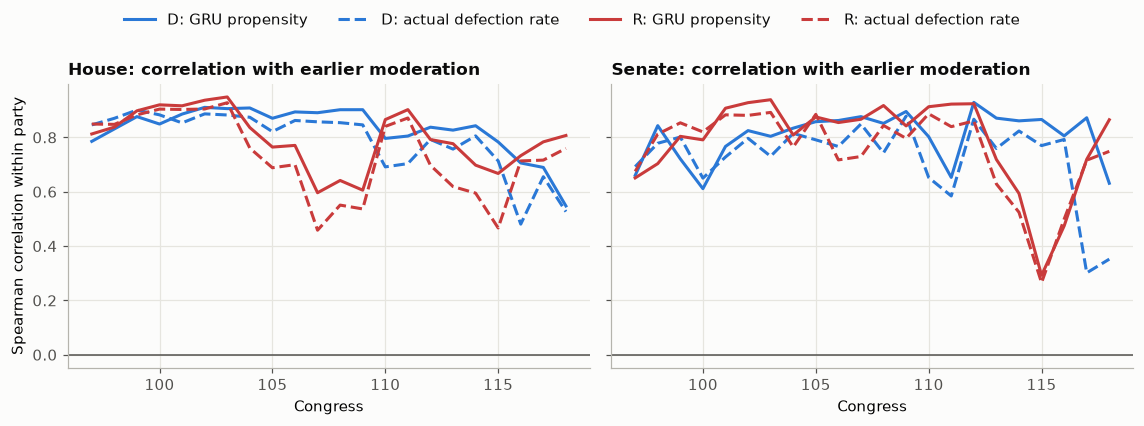

Mean within-party rank correlations by period:


GRU propensity vs previous-Congress Nokken-Poole toward other party  \
chamber party period                                                                                          
House   D     1981-1990 (history only)                                              0.846                     
              1991-2010 (train)                                                     0.878                     
              2011-2014 (validation)                                                0.832                     
              2015-2024 (test)                                                      0.714                     
        R     1981-1990 (history only)                                              0.877                     
              1991-2010 (train)                                                     0.787                     
              2011-2014 (validation)                                                0.784                     
              2015-2024 (test)                                                      0.738                     
Senate  D     1981-1990 (history only)                                              0.720                     
              1991-2010 (train)                                                     0.826                     
              2011-2014 (validation)                                                0.900                     
              2015-2024 (test)                                                      0.807                     
        R     1981-1990 (history only)                                              0.771                     
              1991-2010 (train)                                                     0.887                     
              2011-2014 (validation)                                                0.821                     
              2015-2024 (test)                                                      0.589                     

                                        actual defection vs previous-Congress Nokken-Poole toward other party  \
chamber party period                                                                                            
House   D     1981-1990 (history only)                                              0.871                       
              1991-2010 (train)                                                     0.828                       
              2011-2014 (validation)                                                0.775                       
              2015-2024 (test)                                                      0.636                       
        R     1981-1990 (history only)                                              0.877                       
              1991-2010 (train)                                                     0.724                       
              2011-2014 (validation)                                                0.658                       
              2015-2024 (test)                                                      0.650                       
Senate  D     1981-1990 (history only)                                              0.730                       
              1991-2010 (train)                                                     0.761                       
              2011-2014 (validation)                                                0.813                       
              2015-2024 (test)                                                      0.608                       
        R     1981-1990 (history only)                                              0.809                       
              1991-2010 (train)                                                     0.824                       
              2011-2014 (validation)                                                0.745                       
              2015-2024 (test)                                                      0.551                       

      

In [2]:
rows = []
for (congress, chamber, party), group in states.groupby(["congress", "chamber", "party"]):
    if len(group) < 15:
        continue
    rows.append({"congress": congress, "chamber": chamber, "party": party, "members": len(group),
                 "GRU propensity vs previous-Congress Nokken-Poole toward other party": spearmanr(group["mean_p_gru"], group["np_prev_toward_other"], nan_policy="omit").statistic,
                 "actual defection vs previous-Congress Nokken-Poole toward other party": spearmanr(group["defection_rate"], group["np_prev_toward_other"], nan_policy="omit").statistic,
                 "GRU propensity vs same-Congress Nokken-Poole toward other party": spearmanr(group["mean_p_gru"], group["np_toward_other"]).statistic,
                 "actual defection vs same-Congress Nokken-Poole toward other party": spearmanr(group["defection_rate"], group["np_toward_other"]).statistic,
                 "GRU propensity vs actual defection": spearmanr(group["mean_p_gru"], group["defection_rate"]).statistic})
corr = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
for axis, chamber in zip(axes, ["House", "Senate"]):
    for party in ["D", "R"]:
        part = corr[(corr["chamber"] == chamber) & (corr["party"] == party)]
        axis.plot(part["congress"], part["GRU propensity vs previous-Congress Nokken-Poole toward other party"], color=COLORS[party], label=f"{party}: GRU propensity")
        axis.plot(part["congress"], part["actual defection vs previous-Congress Nokken-Poole toward other party"], color=COLORS[party], linestyle="--",
                  label=f"{party}: actual defection rate")
    axis.axhline(0, color=NEUTRAL, linewidth=1)
    axis.set_title(f"{chamber}: correlation with earlier moderation")
    axis.set_xlabel("Congress")
axes[0].set_ylabel("Spearman correlation within party")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()
print("Mean within-party rank correlations by period:")
corr["period"] = pd.cut(corr["congress"], [96, 101, 111, 113, 118], labels=["1981-1990 (history only)", "1991-2010 (train)", "2011-2014 (validation)", "2015-2024 (test)"])
display(corr.groupby(["chamber", "party", "period"], observed=True)[[c for c in corr.columns if " vs " in c]].mean().round(3))


**What this shows**

Rank correlations within each party, Congress and chamber, with "toward other party" meaning the member's distance from their party's median in the other party's direction.

**This is a description, not a validation.** The GRU's propensity in a Congress is built from the member's earlier votes, including the previous Congress's, which are the votes previous-Congress Nokken-Poole is fitted on. Agreement between them is largely built in.

- **The GRU's propensity tracks earlier moderation closely.** Correlations with the previous Congress's Nokken-Poole position are 0.71 to 0.90 in most chamber, party and period combinations. In the test years they are 0.71 (House Democrats), 0.74 (House Republicans), 0.81 (Senate Democrats) and 0.59 (Senate Republicans).
- **The propensity tracks earlier moderation more closely than actual defection does** (test years: 0.55 to 0.65 for actual defection). That is expected for a smoothed summary of the same earlier votes, and isn't evidence that the GRU learned moderation.
- **It agrees closely with actual defection in the same Congress** (0.81 to 0.95). This is partly hindsight within the Congress, because each prediction uses the member's earlier votes in it.
- **The link weakened for Senate Republicans around the 115th Congress (2017 to 2018),** to about 0.3 for both lines, and for House Republicans in the 2000s. Why isn't tested here.
- **For Senate Democrats in 2021 to 2024, actual defection barely tracks earlier position (about 0.3).** Most of them rarely defected, so their ranking is mostly noise, while the propensity still follows earlier position.
- Same-Congress correlations are similar or slightly higher (test years 0.59 to 0.79).

## Defection is not the same as moderation

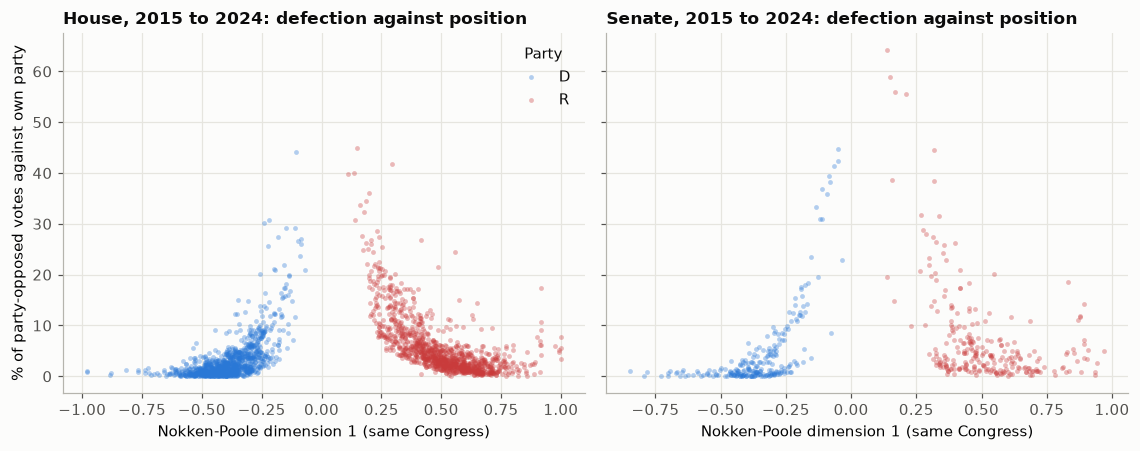

The 10% of members who defect most in each Congress, 2015 to 2024: where they sit within their party


edge           half toward other party  outer half of party
chamber party                                              
House   D                        0.981                0.019
        R                        0.937                0.063
Senate  D                        1.000                0.000
        R                        0.833                0.167

Most frequent defectors in the 117th and 118th Congresses (2021 to 2024):
House


,,,votes,defection_rate,mean_p_gru,np_toward_other,nokken_poole_dim1
bioname,party,state_abbrev,,,,,
"FITZPATRICK, Brian K.",R,PA,1442,0.399,0.381,0.378,0.124
"KATKO, John",R,NY,569,0.337,0.284,0.335,0.161
"KINZINGER, Adam",R,IL,420,0.307,0.231,0.356,0.140
"CHAVEZ-DEREMER, Lori",R,OR,861,0.275,0.267,0.342,0.167
"LAWLER, Michael",R,NY,857,0.263,0.260,0.322,0.187
"PEREZ, Marie Gluesenkamp",D,WA,860,0.260,0.181,0.322,-0.084
"UPTON, Frederick Stephen",R,MI,573,0.260,0.212,0.291,0.205
"KEAN, Thomas",R,NJ,869,0.251,0.247,0.315,0.194
"KILEY, Kevin",R,CA,864,0.211,0.218,0.255,0.254


Senate


,,,votes,defection_rate,mean_p_gru,np_toward_other,nokken_poole_dim1
bioname,party,state_abbrev,,,,,
"COLLINS, Susan Margaret",R,ME,1298,0.616,0.691,0.372,0.144
"MURKOWSKI, Lisa",R,AK,1224,0.558,0.630,0.325,0.190
"GRAHAM, Lindsey O.",R,SC,1204,0.415,0.497,0.198,0.317
"PORTMAN, Robert Jones (Rob)",R,OH,725,0.314,0.379,0.172,0.338
"BLUNT, Roy",R,MO,694,0.274,0.289,0.196,0.314
"TILLIS, Thomas Roland (Thom)",R,NC,1197,0.252,0.278,0.140,0.376
"ROMNEY, Willard Mitt (Mitt)",R,UT,1197,0.244,0.264,0.241,0.275
"ROUNDS, Marion Michael (Mike)",R,SD,1102,0.239,0.264,0.187,0.328
"BURR, Richard M.",R,NC,655,0.229,0.229,0.147,0.363


Senate Republicans defecting most often in 2021 to 2024: defection rate on party-opposed votes by vote type


mean                                              \
vote_type               amendment cloture nomination other passage procedural   
bioname                                                                         
COLLINS, Susan Margaret     0.298   0.765      0.787  0.20   0.550      0.346   
GRAHAM, Lindsey O.          0.082   0.548      0.600  0.00   0.333      0.149   
MURKOWSKI, Lisa             0.228   0.712      0.715  0.25   0.632      0.284   

                                                      size                     \
vote_type               resolution veto override amendment cloture nomination   
bioname                                                                         
COLLINS, Susan Margaret      0.114           0.0       188     443        423   
GRAHAM, Lindsey O.           0.086           0.0       171     405        390   
MURKOWSKI, Lisa              0.059           0.0       184     413        396   

                                                                           
vote_type               other passage procedural resolution veto override  
bioname                                                                    
COLLINS, Susan Margaret     5      20        179         35             5  
GRAHAM, Lindsey O.          5      18        175         35             5  
MURKOWSKI, Lisa             4      19        169         34             5

In [3]:
recent = states[states["congress"].between(114, 118)]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
for axis, chamber in zip(axes, ["House", "Senate"]):
    part = recent[recent["chamber"] == chamber]
    for party in ["D", "R"]:
        p = part[part["party"] == party]
        axis.scatter(p["nokken_poole_dim1"], p["defection_rate"] * 100, s=10, color=COLORS[party], alpha=0.35, linewidths=0, label=party)
    axis.set_title(f"{chamber}, 2015 to 2024: defection against position")
    axis.set_xlabel("Nokken-Poole dimension 1 (same Congress)")
axes[0].set_ylabel("% of party-opposed votes against own party")
axes[0].legend(title="Party")
fig.tight_layout()
plt.show()
# Share of defectors who sit on the party's outer edge rather than toward the other party.
recent = recent.assign(edge=np.where(recent["np_toward_other"] < 0, "outer half of party", "half toward other party"))
keys = recent.groupby(["chamber", "party", "congress"])
rank = keys["defection_rate"].rank(method="first", ascending=False)
top = recent[rank <= np.maximum(1, keys["defection_rate"].transform("size") // 10)]
print("The 10% of members who defect most in each Congress, 2015 to 2024: where they sit within their party")
display(pd.crosstab([top["chamber"], top["party"]], top["edge"], normalize="index").round(3))
print("Most frequent defectors in the 117th and 118th Congresses (2021 to 2024):")
for chamber in ["House", "Senate"]:
    part = states[(states["chamber"] == chamber) & states["congress"].isin([117, 118])]
    part = part.groupby(["bioname", "party", "state_abbrev"], observed=True).agg(
        votes=("votes", "sum"), defection_rate=("defection_rate", "mean"), mean_p_gru=("mean_p_gru", "mean"),
        np_toward_other=("np_toward_other", "mean"), nokken_poole_dim1=("nokken_poole_dim1", "mean"))
    print(chamber)
    display(part.sort_values("defection_rate", ascending=False).head(12).round(3))

print("Senate Republicans defecting most often in 2021 to 2024: defection rate on party-opposed votes by vote type")
recent_votes = pd.read_parquet(OUTPUTS / "predictions.parquet", columns=["congress", "chamber", "bioname", "party_opposed", "vote_type", "defected"])
recent_votes = recent_votes[(recent_votes["chamber"] == "Senate") & recent_votes["congress"].isin([117, 118]) & recent_votes["party_opposed"]
                            & recent_votes["bioname"].isin(["COLLINS, Susan Margaret", "MURKOWSKI, Lisa", "GRAHAM, Lindsey O."])]
display(recent_votes.pivot_table(index="bioname", columns="vote_type", values="defected", aggfunc=["mean", "size"], observed=True).round(3))

### Who defects on which kind of roll call

In [4]:
# All votes, not only party-opposed ones: when the parties agree, defecting means voting against both of them.
# Previous-Congress Nokken-Poole places each member in the half of their party nearer the other party or the outer half.
votes = pd.read_parquet(OUTPUTS / "predictions.parquet", columns=["congress", "chamber", "person", "party", "party_opposed", "defected"])
votes = votes[votes["congress"].between(114, 118)].merge(
    states[["congress", "chamber", "person", "party", "np_prev_toward_other"]], on=["congress", "chamber", "person", "party"], how="left")
votes = votes[votes["np_prev_toward_other"].notna()]
votes["half"] = np.where(votes["np_prev_toward_other"] > 0, "half toward other party", "outer half of party")
votes["kind"] = np.where(votes["party_opposed"], "party-opposed", "parties agree or one tied")
defections = votes[votes["defected"]]
print(f"Defections, 2015 to 2024, by where the member sat in their party in the previous Congress ({len(defections):,} defections "
      f"by members with a previous-Congress score and at least {MIN_VOTES} party-opposed votes):")
display(pd.crosstab([defections["chamber"], defections["party"], defections["kind"]], defections["half"], normalize="index").round(3)
        .join(defections.groupby(["chamber", "party", "kind"]).size().rename("defections")))
print("Defection rate by half and kind of roll call:")
display(votes.pivot_table(index=["chamber", "party", "half"], columns="kind", values="defected", aggfunc="mean").round(4))

Defections, 2015 to 2024, by where the member sat in their party in the previous Congress (121,808 defections by members with a previous-Congress score and at least 50 party-opposed votes):


half toward other party  \
chamber party kind                                                 
House   D     parties agree or one tied                    0.362   
              party-opposed                                0.737   
        R     parties agree or one tied                    0.186   
              party-opposed                                0.706   
Senate  D     parties agree or one tied                    0.179   
              party-opposed                                0.832   
        R     parties agree or one tied                    0.194   
              party-opposed                                0.750   

                                         outer half of party  defections  
chamber party kind                                                        
House   D     parties agree or one tied                0.638       11452  
              party-opposed                            0.263       20532  
        R     parties agree or one tied                0.814       30284  
              party-opposed                            0.294       38765  
Senate  D     parties agree or one tied                0.821        3798  
              party-opposed                            0.168        3698  
        R     parties agree or one tied                0.806        4424  
              party-opposed                            0.250        8855

Defection rate by half and kind of roll call:


kind                                   parties agree or one tied  \
chamber party half                                                 
House   D     half toward other party                     0.0529   
              outer half of party                         0.0858   
        R     half toward other party                     0.0743   
              outer half of party                         0.2958   
Senate  D     half toward other party                     0.0455   
              outer half of party                         0.1885   
        R     half toward other party                     0.0530   
              outer half of party                         0.2119   

kind                                   party-opposed  
chamber party half                                    
House   D     half toward other party         0.0471  
              outer half of party             0.0155  
        R     half toward other party         0.0822  
              outer half of party             0.0309  
Senate  D     half toward other party         0.0643  
              outer half of party             0.0119  
        R     half toward other party         0.1326  
              outer half of party             0.0420

**What this shows**

- **On party-opposed votes, frequent defection belongs to members near the boundary between the parties.** Defection rises steeply as Nokken-Poole approaches the other party and is near zero for most members. The 10% of members who defect most in each Congress sit in the half of their party nearer the other party: 98% of House Democrats, 94% of House Republicans, all Senate Democrats and 83% of Senate Republicans (same-Congress scores, descriptive only).
- **The most frequent defectors in 2021 to 2024 are almost all Republicans:** 10 of the 12 most frequent in the House (led by Fitzpatrick at 40%) and all 12 in the Senate (Collins 62%, Murkowski 56%).
- **Some frequent defectors defect on a narrow kind of vote.** Lindsey Graham defected on 42% of party-opposed votes from a fairly conservative position. He defected on 60% of nominations and 55% of cloture votes, but only 8% of amendments. Collins and Murkowski defected across vote types (23% to 30% of amendments).
- **The prediction target mixes two behaviours.** Using previous-Congress positions:
  - on party-opposed roll calls, 71% to 83% of defections come from the half of the party nearer the other party;
  - on roll calls where the parties agree, 64% to 82% come from the **outer** half. There, House Republicans in the outer half defect on 30% of votes, against 7% for the other half. These are members voting against bipartisan majorities, not crossing to the other party.
- **How to read the second point:**
  - Nokken-Poole places members who vote against bipartisan majorities toward the extremes, partly because of those votes. So this shows that such behaviour persists from one Congress to the next, as much as where the members sit.
  - It covers 122,000 of about 148,000 test defections: members without a previous-Congress score or with fewer than 50 party-opposed votes drop out.
  - Which roll calls where the parties agree are kept depends on the near-unanimous filter, which is computed from the final vote.
- So "defection" means crossing to the other side on party-opposed votes and dissent from the edge on consensus votes. One position score can't capture both.

## What the hidden state holds

Variance explained by the first three components of the average state: [0.384 0.172 0.13 ]
Rank correlation of the first component with each measure, pooled over Congresses, within chamber and party:


,House D,House R,Senate D,Senate R
Nokken-Poole dim 1,0.210,-0.001,0.331,-0.264
Nokken-Poole toward other party,0.076,-0.219,0.294,0.036
distance from centre |Nokken-Poole|,-0.205,-0.001,-0.330,-0.264
actual defection rate,0.399,0.388,0.668,0.531
GRU propensity,0.343,0.405,0.620,0.506


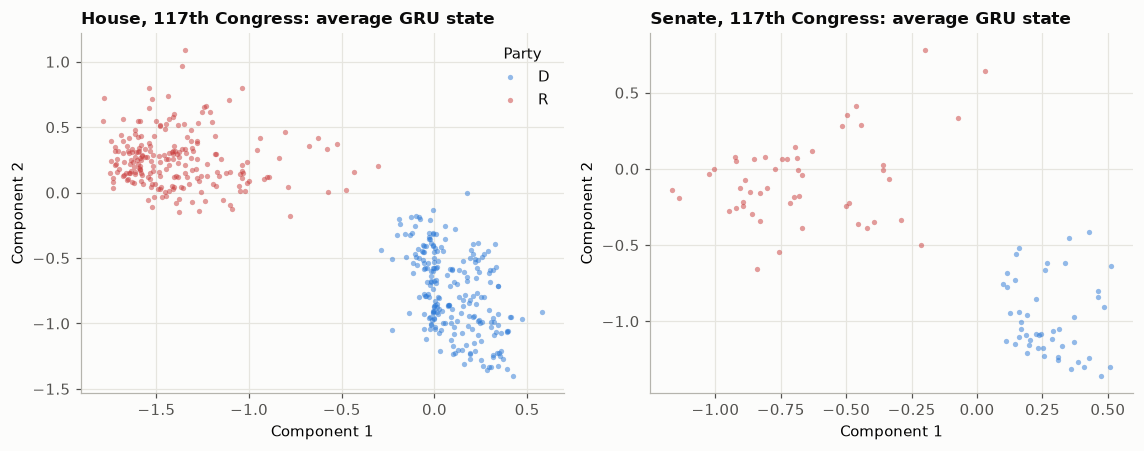

In [5]:
# One trained network gives every member the same state space, so states from different years are comparable
# without alignment, as long as the inputs mean the same thing. That is an assumption, not a test.
pca = PCA(n_components=3).fit(states[hidden])
components = pca.transform(states[hidden])
states["pc1"], states["pc2"] = components[:, 0], components[:, 1]
print("Variance explained by the first three components of the average state:", pca.explained_variance_ratio_.round(3))
checks = {}
for name, column in [("Nokken-Poole dim 1", "nokken_poole_dim1"), ("Nokken-Poole toward other party", "np_toward_other"),
                     ("distance from centre |Nokken-Poole|", "np_extremity"), ("actual defection rate", "defection_rate"), ("GRU propensity", "mean_p_gru")]:
    checks[name] = {f"{chamber} {party}": spearmanr(g["pc1"], g[column], nan_policy="omit").statistic
                    for (chamber, party), g in states.groupby(["chamber", "party"])}
print("Rank correlation of the first component with each measure, pooled over Congresses, within chamber and party:")
display(pd.DataFrame(checks).T.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for axis, chamber in zip(axes, ["House", "Senate"]):
    part = states[(states["chamber"] == chamber) & (states["congress"] == 117)]
    for party in ["D", "R"]:
        p = part[part["party"] == party]
        axis.scatter(p["pc1"], p["pc2"], s=12, color=COLORS[party], alpha=0.5, linewidths=0, label=party)
    axis.set_title(f"{chamber}, 117th Congress: average GRU state")
    axis.set_xlabel("Component 1")
    axis.set_ylabel("Component 2")
axes[0].legend(title="Party")
fig.tight_layout()
plt.show()


**What this shows**

The average states are projected onto their first principal components, fitted on every member-Congress together. One trained network gives every member the same state space, so no alignment is needed across years, as long as the inputs keep the same meaning. That is assumed, not tested. Distances in this projection are used only for description.

- **The first component mainly separates the parties** (Republicans to the left, Democrats to the right in the 117th Congress). Party is an input, so this is built in.
- **Within each party, the first component is moderately related to defection** (rank correlation 0.39 to 0.67 with the actual rate, 0.34 to 0.62 with the GRU propensity) and weakly and inconsistently to Nokken-Poole position (-0.26 to 0.33). These correlations pool all Congresses, including training years, so shifts between Congresses mix into them.
- **The first three components explain 38%, 17% and 13% of the variance,** so the state holds several directions.
- **This doesn't show what the state does or doesn't encode.** The propensity, read from the state, tracks earlier Nokken-Poole closely (above), so position-related information is there. A linear probe per Congress, scored on test years, would be needed to say more.

## Member trajectories

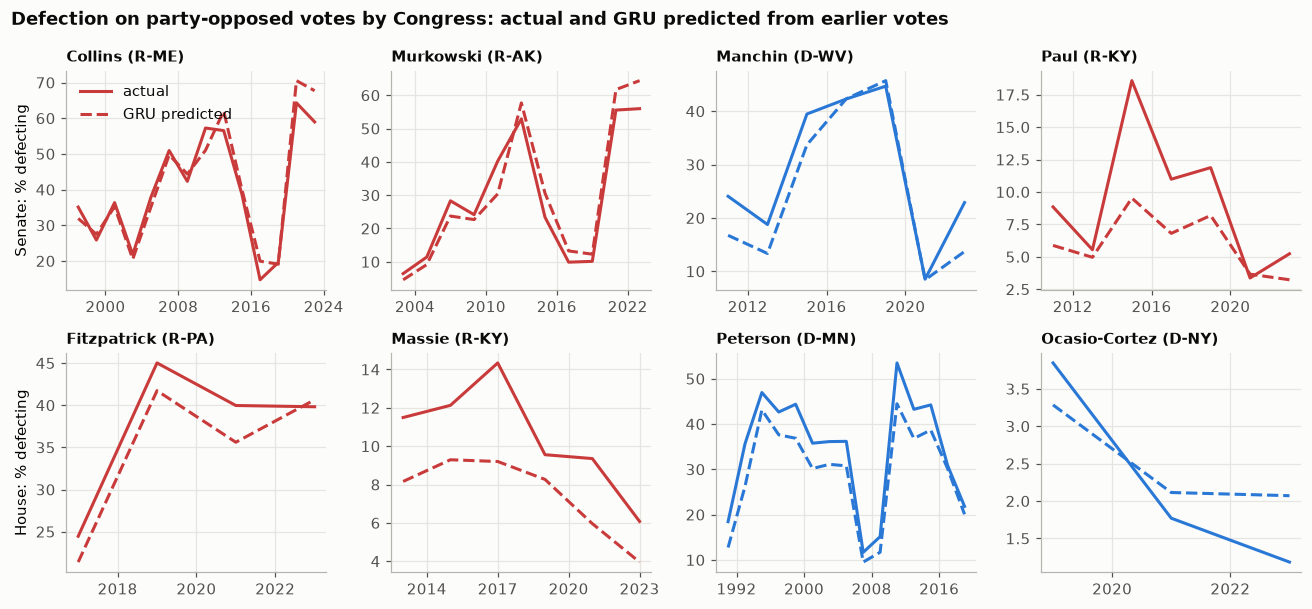

In [6]:
PEOPLE = {"Senate": ["COLLINS, Susan Margaret", "MURKOWSKI, Lisa", "MANCHIN, Joe, III", "PAUL, Rand"],
          "House": ["FITZPATRICK, Brian K.", "MASSIE, Thomas", "PETERSON, Collin Clark", "OCASIO-CORTEZ, Alexandria"]}
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6), sharex=False)
for row, (chamber, names) in enumerate(PEOPLE.items()):
    for column, name in enumerate(names):
        axis = axes[row, column]
        person = states[(states["chamber"] == chamber) & (states["bioname"] == name)].sort_values("congress")
        if person.empty:
            axis.set_title(f"{name}: not found")
            continue
        color = COLORS[person["party"].iloc[0]]
        axis.plot(person["year"], person["defection_rate"] * 100, color=color, label="actual")
        axis.plot(person["year"], person["mean_p_gru"] * 100, color=color, linestyle="--", label="GRU predicted")
        axis.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=4))
        axis.set_title(name.split(",")[0].title() + f" ({person['party'].iloc[0]}-{person['state_abbrev'].iloc[0]})", fontsize=10)
        if column == 0:
            axis.set_ylabel(f"{chamber}: % defecting")
axes[0, 0].legend()
fig.suptitle("Defection on party-opposed votes by Congress: actual and GRU predicted from earlier votes", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()


**What this shows**

Solid lines are actual defection on party-opposed votes; dashed lines are the GRU's average prediction from earlier votes. Values from 1991 to 2010 are in-sample (training years). Values from 1981 to 1990 are outside the training years, but vote types are unknown then.

- **The GRU follows members whose behaviour changes,** with a short lag:
  - Collins and Murkowski: down in 2017 to 2020, up sharply from 2021, when party control changed;
  - Manchin: rising to 45% in 2019, then down under a Democratic Senate.
- **It under-predicts some members who rebel from the outer edge.** Massie is under-predicted in every Congress (for example 14% actual against 9% predicted in 2017), and Paul in 2015 (19% against 10%).
- **Low-defection members are predicted low,** as for Ocasio-Cortez (1% to 4%), though the GRU lags her fall in 2023 (2.1% predicted against 1.2%).
- Peterson, a long-serving Democrat, is tracked from 1991 to 2019, mostly in-sample, through a swing from about 10% to 54% around his party losing its House majority in 2011.
- These are 8 hand-picked members, chosen as known cases, so they illustrate rather than measure.

## Summary

- **The GRU's propensity tracks members' earlier positions:** within-party rank correlations of 0.59 to 0.81 with the previous Congress's Nokken-Poole in the test years. Both are built from the same earlier votes, so this describes the propensity rather than validating it.
- **Frequent defection on party-opposed votes is concentrated among members nearest the other party,** and since 2021 mostly among Republicans. Some frequent defectors, like Graham, defect mainly on one kind of vote (nominations and cloture).
- **"Defection" covers two behaviours:** crossing on party-opposed votes, by moderates, and dissent on consensus votes, by members on the outer edge. Some outer-edge rebels, such as Massie and Paul, are under-predicted.
- **The hidden state's main direction separates the parties.** Within party it is moderately related to defection. What else the state encodes isn't established.
- **Limits:**
  - training years are in-sample;
  - states are averaged over a Congress, which hides change within it;
  - comparing states across years assumes inputs keep their meaning;
  - descriptions of behaviour on roll calls that reached the floor, not of beliefs.